# Preprocesamiento común de egresos hospitalarios 2023–2025

Cada sección explica una etapa del preprocesamiento. Selecciona el kernel del proyecto y pulsa
**Ejecutar todo**. El bucle al final aplica las etapas a 2023, 2024 y 2025 en orden.
Las tablas y figuras aparecen debajo de la celda de su etapa, en bloques separados por año.
La última celda muestra el resumen de la base común.

Cada fila representa un egreso hospitalario. `ANO_FUENTE` indica el año del ZIP e `ID_REGISTRO`
indica el número de fila dentro del CSV. Juntos permiten ubicar el registro en su fuente.

In [61]:
from base64 import b64encode
from contextlib import ExitStack
from html import escape
from pathlib import Path
from tempfile import TemporaryDirectory
from zipfile import ZipFile
from io import BytesIO
import hashlib
import platform
from importlib.metadata import version

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

FUENTES = {
    2023: ("EGRESOS_2023.csv", "cp1252"),
    2024: ("EGR_DATOS_ABIERTO_2024.csv", "utf-8"),
    2025: ("EGR_DATOS_ABIERTO_2025.csv", "utf-8"),
}
FILAS_ESPERADAS = {2023: 1_612_267, 2024: 1_667_349, 2025: 1_705_514}

RAIZ = Path.cwd()
ORIGINALES = RAIZ / "datos" / "originales"
PROCESADOS = RAIZ / "datos" / "procesados"
ARCHIVO_COMUN = PROCESADOS / "egresos_2023_2025_base_comun.parquet"
PROCESADOS.mkdir(parents=True, exist_ok=True)

UMBRAL_REVISION_DIAS = 365
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 85)
plt.rcParams.update({"figure.figsize": (10, 4), "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False})

paquetes = ["pandas", "numpy", "matplotlib", "openpyxl", "pyarrow"]
versiones = {paquete: version(paquete) for paquete in paquetes}
display(pd.Series({"Python": platform.python_version(), **versiones}, name="versión").to_frame())

,versión
Python,3.13.5
pandas,3.1.1
numpy,2.5.4
matplotlib,3.11.2
openpyxl,3.1.5
pyarrow,26.0.1


In [62]:
salidas_por_etapa = {}


def reservar_salidas(etapa):
    salidas_por_etapa[etapa.__name__] = {
        anio: display(HTML(f"<em>{anio} · pendiente de procesar</em>"), display_id=True)
        for anio in FUENTES
    }


def ejecutar_etapa(anio, etapa, *argumentos):
    with capture_output() as salida:
        resultado = etapa(*argumentos)

    bloques = [f"<h4>{anio}</h4>"]
    for mensaje in (salida.stdout, salida.stderr):
        if mensaje:
            bloques.append(f"<pre>{escape(mensaje.rstrip())}</pre>")
    for vista in salida.outputs:
        formatos = vista.data
        if "image/png" in formatos:
            imagen = formatos["image/png"]
            if isinstance(imagen, bytes):
                imagen = b64encode(imagen).decode("ascii")
            bloques.append(f'<img alt="Gráfico de {anio}" style="max-width:100%" src="data:image/png;base64,{imagen}">')
        elif "text/html" in formatos:
            bloques.append(formatos["text/html"])
        elif "text/plain" in formatos:
            bloques.append(f"<pre>{escape(formatos['text/plain'])}</pre>")

    salidas_por_etapa[etapa.__name__][anio].update(HTML("".join(bloques)))
    return resultado

## 1. Carga del CSV y del diccionario

Los CSV usan punto y coma. El archivo de 2023 se lee con Windows-1252 y los de 2024 y 2025 con
UTF-8. Los códigos se leen como texto para conservar los ceros iniciales. La lectura mantiene
vacíos, `*` y el texto `NULL` tal como vienen. La huella SHA-256 identifica el ZIP utilizado.

Se leen el CSV y el diccionario directamente desde el ZIP. El diccionario denomina
`DIAS_ESTAD` al campo `DIAS_ESTADA` del CSV. El preprocesamiento se aplica a las 16 columnas
compartidas. Se incorpora además `ERROR` con los valores del CSV de 2025, cuyo significado
está sin documentar. En 2023 y 2024 el campo queda ausente porque los CSV no lo traen.

`DIAG2` corresponde a causa externa, no a una segunda enfermedad. Sus vacíos pueden ser estructurales.
La edad es agrupada y la pertenencia al SNSS no equivale a identificar hospitales públicos o clínicas privadas.

In [63]:
def cargar_fuente(anio, nombre_csv, codificacion):
    archivo_zip = ORIGINALES / f"EGRESOS_{anio}.zip"
    with ZipFile(archivo_zip) as archivo:
        contenido_zip = pd.DataFrame({"archivo": archivo.namelist(),
                                     "bytes_sin_comprimir": [a.file_size for a in archivo.infolist()]})
        with archivo.open(nombre_csv) as csv:
            fuente = pd.read_csv(csv, sep=";", encoding=codificacion, dtype="string", keep_default_na=False)
        libro = BytesIO(archivo.read("Diccionario BD egresos hospitalario.xlsx"))
        diccionario = pd.read_excel(libro, sheet_name="Hoja1", dtype="string")
        cie10 = pd.read_excel(libro, sheet_name="codigo CIE-10", header=8, dtype="string")

    originales = fuente.drop(columns="ERROR", errors="ignore")
    assert originales.shape[1] == 16, "Se esperaban 16 columnas comunes."

    sha256 = hashlib.sha256(archivo_zip.read_bytes()).hexdigest()
    print(f"Fuente {anio} | Registros: {len(originales):,} | Columnas del CSV: {fuente.shape[1]}")
    print("SHA-256 del ZIP:", sha256)
    display(contenido_zip)
    display(HTML("<strong>Muestra del CSV original</strong>"))
    display(fuente.head(5)[["GRUPO_EDAD", "COMUNA_RESIDENCIA", "GLOSA_COMUNA_RESIDENCIA", "DIAG1", "DIAS_ESTADA"]])

    diccionario.columns = ["variable", "descripcion_diccionario"]
    diccionario["variable"] = diccionario["variable"].str.strip().replace({"DIAS_ESTAD": "DIAS_ESTADA"})
    descripcion_variables = pd.DataFrame({"variable": originales.columns})
    descripcion_variables = descripcion_variables.merge(diccionario, on="variable", how="left")
    descripcion_variables["descripcion_diccionario"] = descripcion_variables["descripcion_diccionario"].fillna(
        "No definida en el diccionario entregado; significado pendiente de confirmar")
    descripcion_variables["tipo_lectura"] = originales.dtypes.astype(str).values
    descripcion_variables["valores_distintos"] = originales.nunique().values
    descripcion_variables["rol"] = "Categórica o código; no representa una cantidad"
    descripcion_variables.loc[descripcion_variables["variable"].eq("DIAS_ESTADA"), "rol"] = "Cantidad de días de estadía"
    descripcion_variables.loc[descripcion_variables["variable"].eq("ANO_EGRESO"), "rol"] = "Año de referencia"
    display(descripcion_variables)
    return fuente, originales, cie10, descripcion_variables


reservar_salidas(cargar_fuente)

## 2. Exploración inicial

Se muestran las estadísticas descriptivas de la estadía y las frecuencias de la condición de egreso.
El gráfico de 1–60 días amplía ese tramo. La distribución completa incluye las estadías extremas.

,dias
count,1612267.0
mean,6.223
std,50.189
min,1.0
25%,1.0
50%,2.0
75%,6.0
90%,13.0
95%,21.0
99%,52.0

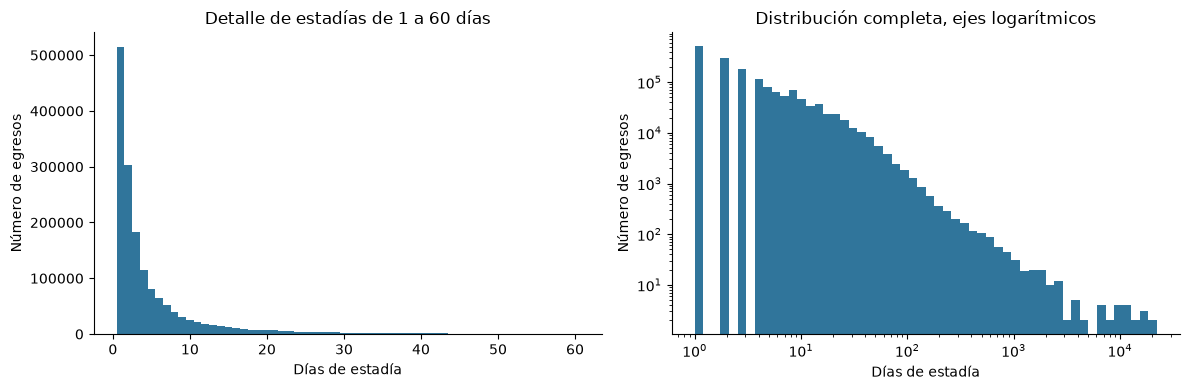

,dias
count,1667349.0
mean,6.092
std,40.363
min,1.0
25%,1.0
50%,2.0
75%,6.0
90%,13.0
95%,21.0
99%,51.0

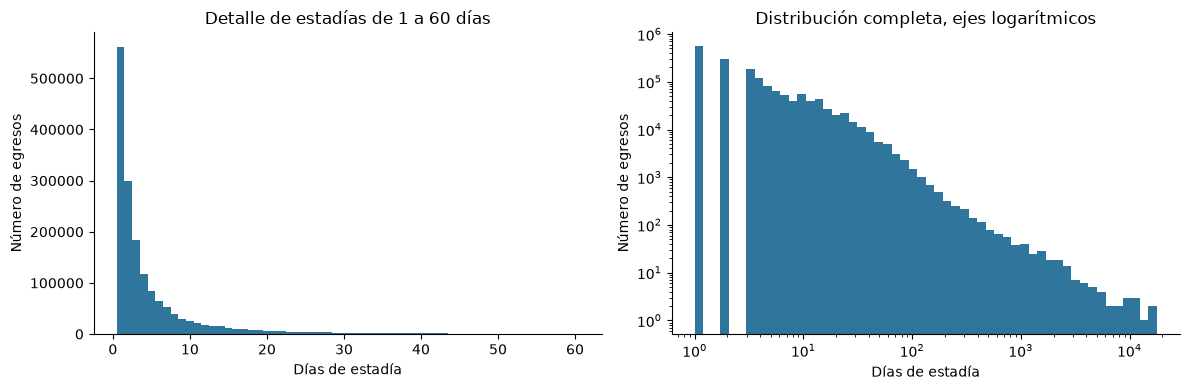

,dias
count,1705514.0
mean,6.09
std,44.469
min,1.0
25%,1.0
50%,2.0
75%,6.0
90%,13.0
95%,21.0
99%,51.0

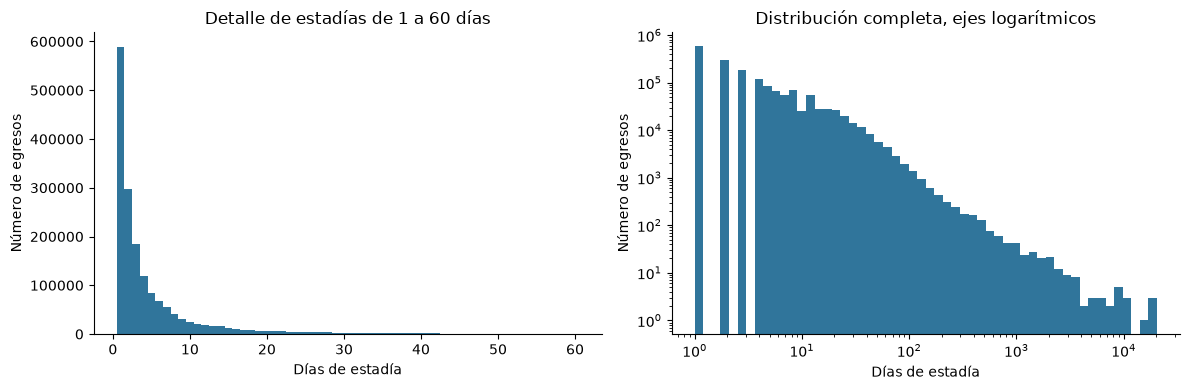

In [64]:
def explorar_fuente(originales, figuras):
    dias_originales = pd.to_numeric(originales["DIAS_ESTADA"], errors="coerce")
    resumen_estadia = dias_originales.describe(percentiles=[.25, .50, .75, .90, .95, .99]).to_frame("dias")
    frecuencia_condicion = originales["CONDICION_EGRESO"].value_counts().rename_axis("codigo").to_frame("registros")
    frecuencia_condicion["condicion"] = frecuencia_condicion.index.map({"1": "Vivo", "2": "Fallecido"})
    frecuencia_condicion["porcentaje"] = 100 * frecuencia_condicion["registros"] / len(originales)
    display(resumen_estadia.round(3))
    display(frecuencia_condicion.round(3))

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    ejes[0].hist(dias_originales[dias_originales.between(1, 60)], bins=np.arange(.5, 61.5), color="#30759b")
    ejes[0].set(title="Detalle de estadías de 1 a 60 días", xlabel="Días de estadía", ylabel="Número de egresos")
    ejes[1].hist(dias_originales.dropna(), bins=np.geomspace(1, dias_originales.max() + 1, 55), color="#30759b")
    ejes[1].set_xscale("log")
    ejes[1].set_yscale("log")
    ejes[1].set(title="Distribución completa, ejes logarítmicos", xlabel="Días de estadía", ylabel="Número de egresos")
    fig.tight_layout()
    fig.savefig(figuras / "01_distribucion_estadia.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


reservar_salidas(explorar_fuente)

## 3. Revisión de calidad

Se cuentan vacíos, asteriscos, el texto literal `NULL`, caracteres dañados y repeticiones.
En los tres archivos, `NULL` en región se asocia con la glosa «Extranjero».
El asterisco indica falta de información cuyo motivo está sin documentar.

Se cuentan las filas con los 16 campos comunes iguales dentro de cada año. Pueden corresponder
a egresos distintos, por lo que se conservan.

,vacios,asteriscos,texto_NULL,caracter_danado,valores_distintos,porcentaje_vacio,porcentaje_asterisco
variable,,,,,,,
PERTENENCIA_ESTABLECIMIENTO_SALU,0,128108,0,0,3,0.0,7.95
SEXO,0,128108,0,0,3,0.0,7.95
GRUPO_EDAD,0,128108,0,0,12,0.0,7.95
ETNIA,0,128108,0,0,3,0.0,7.95
GLOSA_PAIS_ORIGEN,0,128108,0,0,3,0.0,7.95
COMUNA_RESIDENCIA,0,128108,0,0,341,0.0,7.95
GLOSA_COMUNA_RESIDENCIA,0,128108,0,0,341,0.0,7.95
REGION_RESIDENCIA,0,128108,661,0,19,0.0,7.95
GLOSA_REGION_RESIDENCIA,0,128108,0,0,19,0.0,7.95

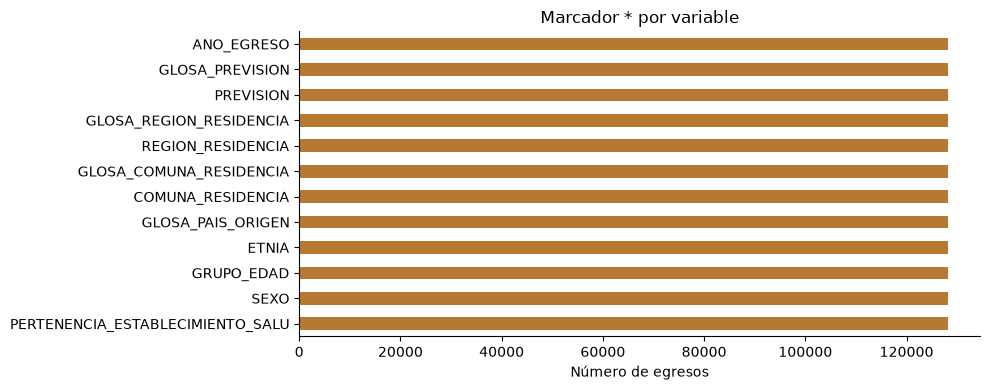

,vacios,asteriscos,texto_NULL,caracter_danado,valores_distintos,porcentaje_vacio,porcentaje_asterisco
variable,,,,,,,
PERTENENCIA_ESTABLECIMIENTO_SALU,0,124508,0,0,3,0.0,7.47
SEXO,0,124508,0,0,3,0.0,7.47
GRUPO_EDAD,0,124508,0,62886,12,0.0,7.47
ETNIA,31,124508,0,0,4,0.0,7.47
GLOSA_PAIS_ORIGEN,0,124508,0,0,3,0.0,7.47
COMUNA_RESIDENCIA,0,124508,0,0,339,0.0,7.47
GLOSA_COMUNA_RESIDENCIA,0,124508,0,393067,339,0.0,7.47
REGION_RESIDENCIA,0,124508,931,0,19,0.0,7.47
GLOSA_REGION_RESIDENCIA,0,124508,0,518500,19,0.0,7.47

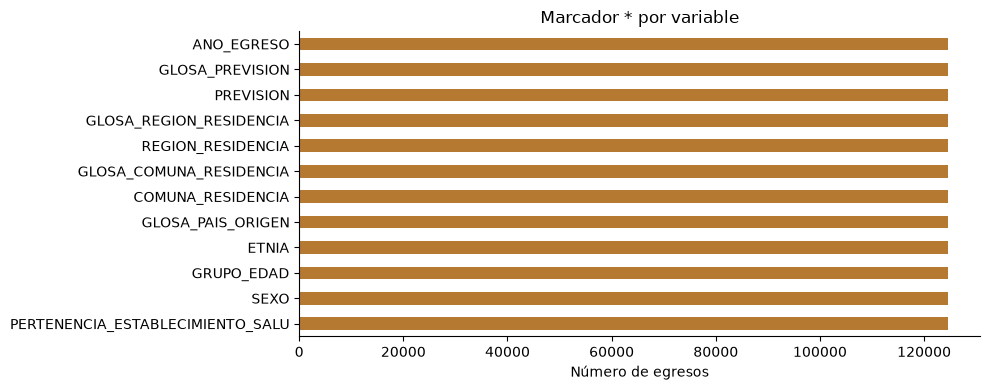

,vacios,asteriscos,texto_NULL,caracter_danado,valores_distintos,porcentaje_vacio,porcentaje_asterisco
variable,,,,,,,
PERTENENCIA_ESTABLECIMIENTO_SALU,0,118961,0,0,3,0.0,6.98
SEXO,0,118961,0,0,4,0.0,6.98
GRUPO_EDAD,0,118961,0,63876,12,0.0,6.98
ETNIA,0,118961,0,0,3,0.0,6.98
GLOSA_PAIS_ORIGEN,0,118961,0,0,3,0.0,6.98
COMUNA_RESIDENCIA,0,118961,0,0,341,0.0,6.98
GLOSA_COMUNA_RESIDENCIA,0,118961,0,400569,341,0.0,6.98
REGION_RESIDENCIA,0,118961,762,0,19,0.0,6.98
GLOSA_REGION_RESIDENCIA,0,118961,0,530319,19,0.0,6.98

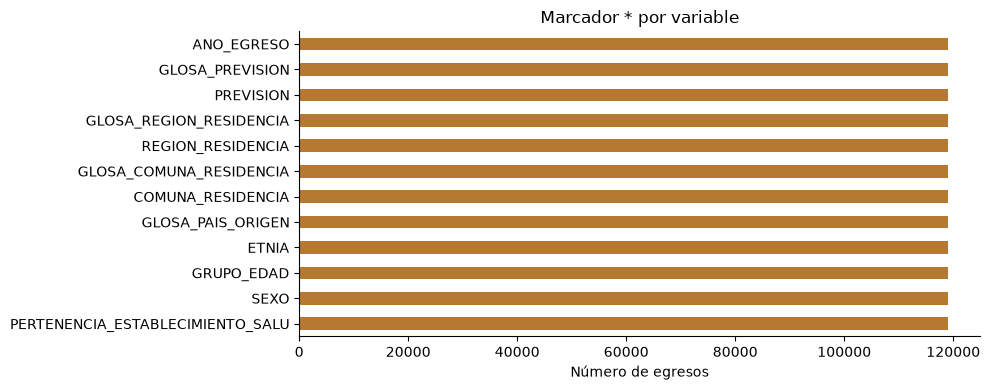

In [65]:
def revisar_calidad(fuente, originales, figuras):
    calidad_inicial = pd.DataFrame({
        "vacios": fuente.eq("").sum(),
        "asteriscos": fuente.eq("*").sum(),
        "texto_NULL": fuente.eq("NULL").sum(),
        "caracter_danado": fuente.apply(lambda columna: columna.str.contains("\ufffd", regex=False).sum()),
        "valores_distintos": fuente.nunique(),
    }).rename_axis("variable")
    calidad_inicial["porcentaje_vacio"] = 100 * calidad_inicial["vacios"] / len(originales)
    calidad_inicial["porcentaje_asterisco"] = 100 * calidad_inicial["asteriscos"] / len(originales)
    display(calidad_inicial.round(2))
    display(originales.loc[originales["REGION_RESIDENCIA"].eq("NULL"),
                           ["REGION_RESIDENCIA", "GLOSA_REGION_RESIDENCIA"]].value_counts().to_frame("registros"))

    variables_explorar = ["PERTENENCIA_ESTABLECIMIENTO_SALU", "SEXO", "GRUPO_EDAD", "ETNIA",
                         "GLOSA_PAIS_ORIGEN", "REGION_RESIDENCIA", "PREVISION", "ANO_EGRESO"]
    frecuencias = []
    for variable in variables_explorar:
        tabla = originales[variable].value_counts(dropna=False).rename_axis("valor").reset_index(name="registros")
        tabla.insert(0, "variable", variable)
        tabla["porcentaje"] = 100 * tabla["registros"] / len(originales)
        frecuencias.append(tabla)
    frecuencias_categoricas = pd.concat(frecuencias, ignore_index=True)
    display(frecuencias_categoricas.round(3))

    fig, ax = plt.subplots(figsize=(10, 4))
    conteos = calidad_inicial.loc[calidad_inicial["asteriscos"].gt(0), "asteriscos"]
    conteos.plot.barh(ax=ax, color="#b67932")
    ax.set(title="Marcador * por variable", xlabel="Número de egresos", ylabel="")
    fig.tight_layout()
    fig.savefig(figuras / "02_asteriscos_por_variable.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    repetidas_adicionales = int(originales.duplicated().sum())
    en_grupo_repetido = originales.duplicated(keep=False)
    resumen_repeticiones = pd.Series({
        "filas_totales": len(originales),
        "combinaciones_distintas_de_los_16_campos_comunes": len(originales) - repetidas_adicionales,
        "repeticiones_adicionales": repetidas_adicionales,
        "filas_que_pertenecen_a_grupos_repetidos": int(en_grupo_repetido.sum()),
    }, name="registros").to_frame()
    display(resumen_repeticiones)
    return calidad_inicial, en_grupo_repetido, repetidas_adicionales


reservar_salidas(revisar_calidad)

## 4. Transformaciones comunes

Se retiran espacios externos, se representan vacíos y `*` como ausentes y se conservan marcas de origen.
Esto expresa la falta de información, sin atribuirle una causa ni imputar valores. `NULL` permanece intacto.
En `GRUPO_EDAD` se usa «Menor de 1 año» tanto para «menor de un año» como para su variante con
un carácter dañado. También se corrige la etiqueta «90 y más» cuando está dañada. Las glosas
geográficas de origen se conservan y se añaden versiones corregidas por código.
Las conversiones numéricas se contabilizan aparte de los cambios de contenido.

In [66]:
def transformar_datos(fuente, originales, en_grupo_repetido, anio):
    datos = originales.copy()
    datos.insert(0, "ID_REGISTRO", np.arange(1, len(datos) + 1, dtype=np.int64))
    datos.insert(1, "ANO_FUENTE", np.int16(anio))
    datos["ERROR"] = fuente.get("ERROR", pd.NA)
    datos["TIENE_ASTERISCO"] = originales.eq("*").any(axis=1)
    datos["TIENE_TEXTO_DANADO"] = originales.apply(
        lambda columna: columna.str.contains("\ufffd", regex=False)).any(axis=1)
    datos["EN_GRUPO_REPETIDO"] = en_grupo_repetido.to_numpy()
    datos["DIAG2_VACIO_ORIGEN"] = originales["DIAG2"].eq("")

    sin_espacios = originales.apply(lambda columna: columna.str.strip())
    cambio_espacios = originales.ne(sin_espacios)
    vacios = sin_espacios.eq("")
    asteriscos = sin_espacios.eq("*")
    datos[originales.columns] = sin_espacios.replace({"": pd.NA, "*": pd.NA})

    etiquetas_edad = {
        "menor de un año": "Menor de 1 año",
        "menor de un a\ufffdo": "Menor de 1 año",
        "90 y m\ufffds": "90 y más",
    }
    cambio_edad = datos["GRUPO_EDAD"].isin(etiquetas_edad)
    datos["GRUPO_EDAD"] = datos["GRUPO_EDAD"].replace(etiquetas_edad)
    datos["TEXTO_DANADO_PENDIENTE"] = datos[["GLOSA_COMUNA_RESIDENCIA", "GLOSA_REGION_RESIDENCIA"]].apply(
        lambda columna: columna.str.contains("\ufffd", regex=False, na=False)).any(axis=1)

    columnas_numericas = ["DIAS_ESTADA", "ANO_EGRESO", "CONDICION_EGRESO", "ERROR"]
    conversiones_tipo = 0
    valores_no_convertibles = {}
    for columna in columnas_numericas:
        valores = pd.to_numeric(datos[columna], errors="coerce")
        valores_no_convertibles[columna] = int((datos[columna].notna() & valores.isna()).sum())
        conversiones_tipo += int(valores.notna().sum())
        datos[columna] = valores.astype("Int64")

    codigos_antes = datos[["DIAG1", "DIAG2"]].copy()
    for columna in ["DIAG1", "DIAG2"]:
        datos[columna] = datos[columna].str.upper().str.replace(".", "", regex=False)
    cambio_codigos = codigos_antes.ne(datos[["DIAG1", "DIAG2"]]).fillna(False)

    transformaciones = pd.DataFrame([
        ["Retirar espacios externos", "Evitar diferencias por formato", int(cambio_espacios.sum().sum()), int(cambio_espacios.any(axis=1).sum())],
        ["Vacíos a ausentes", "Representar ausencia sin inventar valores", int(vacios.sum().sum()), int(vacios.any(axis=1).sum())],
        ["Asteriscos a ausentes", "Mantener la falta de información y su marca de origen", int(asteriscos.sum().sum()), int(asteriscos.any(axis=1).sum())],
        ["Unificar etiquetas de edad", "Usar los mismos nombres de grupo en los tres años", int(cambio_edad.sum()), int(cambio_edad.sum())],
        ["Uniformar códigos CIE-10", "Usar mayúsculas y códigos sin puntos para el cruce", int(cambio_codigos.sum().sum()), int(cambio_codigos.any(axis=1).sum())],
        ["Convertir tipos numéricos", "Guardar cantidades y códigos con tipo entero", conversiones_tipo, int(datos[columnas_numericas].notna().any(axis=1).sum())],
    ], columns=["transformacion", "motivo", "celdas_afectadas", "registros_afectados"])

    display(transformaciones)
    display(HTML("<strong>Etiquetas de edad antes y después</strong>"))
    cambios_de_edad = pd.DataFrame({
        "Etiqueta en el CSV": originales.loc[cambio_edad, "GRUPO_EDAD"],
        "Etiqueta en la base": datos.loc[cambio_edad, "GRUPO_EDAD"],
    }).value_counts().reset_index(name="Egresos")
    display(cambios_de_edad)
    display(pd.Series(valores_no_convertibles, name="valores_no_convertibles").to_frame())
    return datos, transformaciones, valores_no_convertibles


reservar_salidas(transformar_datos)

### Corrección de glosas geográficas mediante códigos oficiales

Los CSV de 2024 y 2025 ya contienen `�` (U+FFFD) donde se perdió una letra.
Se conservan las glosas existentes y se crean versiones con sufijo `_CORREGIDA` mediante el código
de comuna o región. El estado distingue reparación de caracteres, normalización del nombre,
coincidencia, categoría especial y ausencia de correspondencia.

**Fuente:** [capa DPA publicada por la SMA](https://ideserver.sma.gob.cl/arcgis/rest/services/IDE/Limites/MapServer/2),
con metadatos del Grupo de Trabajo de División Político Administrativa (2023), integrado por
DIFROL, SUBDERE, IGM, INE y CIREN. Campos: `CUT_COM`, `COMUNA`, `CUT_REG`, `REGION`.
Referencia de códigos: [CUT de SUBDERE, actualización 2018](https://www.subdere.gov.cl/documentacion/c%C3%B3digos-%C3%BAnicos-territoriales-actualizados-al-06-de-septiembre-2018).

Consulta: **2026-11-08**. Se conserva una copia CSV de 345 comunas y 16 regiones para ejecución sin conexión.
La capa no incluye Antártica (`12202`); no hay filas con ese código en esta fuente de egresos.
[Consulta de origen](https://ideserver.sma.gob.cl/arcgis/rest/services/IDE/Limites/MapServer/2/query?where=1%3D1&outFields=CUT_COM%2CCOMUNA%2CCUT_REG%2CREGION&returnGeometry=false&f=json). La huella de la copia utilizada se muestra al leerla.

`99999`/`99` (Ignorada), `88888`/`NULL` (Extranjero) y los ausentes se conservan, sin asignarles
territorios nacionales. Un código no encontrado mantiene su glosa y se informa para revisión.
Cambios como `De Los Lagos → Los Lagos` se cuentan como normalización, separados de la reparación de `�`.

In [67]:
def corregir_glosas_geograficas(datos, transformaciones):
    archivo_geografico = ORIGINALES / "catalogo_geografico_dpa_2023.csv"
    catalogo_geografico = pd.read_csv(archivo_geografico, dtype="string", encoding="utf-8-sig")
    mapa_comunas = catalogo_geografico.set_index("CUT_COM")["COMUNA"]
    mapa_regiones = catalogo_geografico[["CUT_REG", "REGION"]].drop_duplicates().set_index("CUT_REG")["REGION"]
    assert mapa_comunas.index.is_unique and mapa_regiones.index.is_unique, "Cada código debe tener un solo nombre."
    print("SHA-256 del catálogo geográfico:", hashlib.sha256(archivo_geografico.read_bytes()).hexdigest())

    cambios_geograficos = pd.DataFrame(index=datos.index)
    filas_transformacion_geografica = []
    campos_geograficos = [
        ("COMUNA", "COMUNA_RESIDENCIA", "GLOSA_COMUNA_RESIDENCIA", mapa_comunas, ["99999", "88888"]),
        ("REGION", "REGION_RESIDENCIA", "GLOSA_REGION_RESIDENCIA", mapa_regiones, ["99", "NULL"]),
    ]
    for nivel, codigo, glosa, correspondencia, especiales in campos_geograficos:
        nombre_oficial = datos[codigo].map(correspondencia)
        datos[glosa + "_CORREGIDA"] = nombre_oficial.fillna(datos[glosa])
        danado = datos[glosa].str.contains("\ufffd", regex=False, na=False)
        cambiado = nombre_oficial.notna() & datos[glosa].ne(nombre_oficial).fillna(True)
        estado = pd.Series("SIN_CORRESPONDENCIA", index=datos.index, dtype="string")
        estado.loc[datos[codigo].isna()] = "SIN_DATO"
        estado.loc[datos[codigo].isin(especiales)] = "CATEGORIA_ESPECIAL"
        estado.loc[nombre_oficial.notna()] = "COINCIDE"
        estado.loc[cambiado & ~danado] = "NORMALIZADA"
        estado.loc[cambiado & danado] = "CORREGIDA"
        datos["ESTADO_CORRECCION_" + nivel] = estado
        cambios_geograficos[nivel] = cambiado
        cantidad = int(cambiado.sum())
        filas_transformacion_geografica.append([
            "Crear glosa corregida de " + nivel.lower(),
            "Cruce por código con DPA 2023; se conserva la glosa de origen", cantidad, cantidad])

    glosas_corregidas = ["GLOSA_COMUNA_RESIDENCIA_CORREGIDA", "GLOSA_REGION_RESIDENCIA_CORREGIDA"]
    datos["TEXTO_DANADO_PENDIENTE"] = datos[glosas_corregidas].apply(
        lambda columna: columna.str.contains("\ufffd", regex=False, na=False)).any(axis=1)
    resumen_geografico = pd.DataFrame({nivel: datos["ESTADO_CORRECCION_" + nivel].value_counts()
                                      for nivel in ["COMUNA", "REGION"]})
    resumen_geografico = resumen_geografico.reindex(
        ["CORREGIDA", "NORMALIZADA", "COINCIDE", "CATEGORIA_ESPECIAL", "SIN_DATO", "SIN_CORRESPONDENCIA"]
    ).fillna(0).astype(int).rename_axis("estado")
    transformaciones = pd.concat([
        transformaciones, pd.DataFrame(filas_transformacion_geografica, columns=transformaciones.columns)
    ], ignore_index=True)
    display(resumen_geografico)
    for nivel, codigo, glosa, correspondencia, especiales in campos_geograficos:
        pendientes = datos.loc[datos["ESTADO_CORRECCION_" + nivel].eq("SIN_CORRESPONDENCIA"), [codigo, glosa]]
        print("Sin correspondencia de " + nivel.lower() + ":", len(pendientes))
        display(pendientes.value_counts(dropna=False).to_frame("registros"))
    display(HTML("<strong>Ejemplo de glosa geográfica por código de comuna</strong>"))
    display(datos.loc[datos["COMUNA_RESIDENCIA"].eq("10403"),
                      ["COMUNA_RESIDENCIA", "GLOSA_COMUNA_RESIDENCIA", "GLOSA_COMUNA_RESIDENCIA_CORREGIDA"]]
            .value_counts().to_frame("registros"))
    display(
        datos.loc[
            datos["ESTADO_CORRECCION_COMUNA"] == "CORREGIDA",
            ["GLOSA_COMUNA_RESIDENCIA", "GLOSA_COMUNA_RESIDENCIA_CORREGIDA"]
        ].drop_duplicates().sort_values("GLOSA_COMUNA_RESIDENCIA_CORREGIDA")
    )
    return transformaciones, resumen_geografico, int(cambios_geograficos.any(axis=1).sum())


reservar_salidas(corregir_glosas_geograficas)

,COMUNA,REGION
estado,,
CORREGIDA,0,0
NORMALIZADA,33856,875143
COINCIDE,1437378,596091
CATEGORIA_ESPECIAL,12925,12925
SIN_DATO,128108,128108
SIN_CORRESPONDENCIA,0,0
,,registros
COMUNA_RESIDENCIA,GLOSA_COMUNA_RESIDENCIA,
,,registros


,COMUNA,REGION
estado,,
CORREGIDA,393067,518500
NORMALIZADA,0,378621
COINCIDE,1130649,626595
CATEGORIA_ESPECIAL,19125,19125
SIN_DATO,124508,124508
SIN_CORRESPONDENCIA,0,0
,,registros
COMUNA_RESIDENCIA,GLOSA_COMUNA_RESIDENCIA,
,,registros


,COMUNA,REGION
estado,,
CORREGIDA,400569,530319
NORMALIZADA,0,393383
COINCIDE,1169012,645879
CATEGORIA_ESPECIAL,16972,16972
SIN_DATO,118961,118961
SIN_CORRESPONDENCIA,0,0
,,registros
COMUNA_RESIDENCIA,GLOSA_COMUNA_RESIDENCIA,
,,registros


### Incorporación de información CIE-10

Se normalizan los códigos del diccionario y se incorpora la categoría, descripción y capítulo del diagnóstico
principal. Es un enriquecimiento descriptivo; no selecciona atributos para un algoritmo. Los códigos completos
se conservan. Se distingue coincidencia exacta, coincidencia solo de categoría y ausencia de correspondencia.

Los códigos no encontrados se conservan para revisión: no se declaran inválidos. La marca de coincidencia
de `DIAG2` distingue ausencia de causa externa y código sin correspondencia. El diagnóstico principal es
información del egreso, lo que limita su interpretación en los análisis posteriores.

In [68]:
def incorporar_cie10(datos, originales, cie10):
    cie10.columns = ["codigo", "diagnostico", "capitulo", "glosa_capitulo", "grupo", "glosa_grupo",
                     "categoria", "glosa_categoria"]
    sin_cruce_antes = int((~originales["DIAG1"].isin(cie10["codigo"])).sum())
    cie10 = cie10.dropna(subset=["codigo"]).copy()
    for columna in cie10.columns:
        cie10[columna] = cie10[columna].str.strip()
    for columna in ["codigo", "categoria", "grupo", "capitulo"]:
        cie10[columna] = cie10[columna].str.upper().str.replace(".", "", regex=False)
    cie_por_codigo = cie10.set_index("codigo")
    categorias_cie = cie10[["categoria", "glosa_categoria", "capitulo", "glosa_capitulo"]].drop_duplicates()
    categorias_cie = categorias_cie.set_index("categoria")

    datos["DIAG1_CATEGORIA"] = datos["DIAG1"].str[:3]
    datos["DIAG1_DESCRIPCION"] = datos["DIAG1"].map(cie_por_codigo["diagnostico"])
    datos["DIAG1_GLOSA_CATEGORIA"] = datos["DIAG1_CATEGORIA"].map(categorias_cie["glosa_categoria"])
    datos["DIAG1_CAPITULO"] = datos["DIAG1_CATEGORIA"].map(categorias_cie["capitulo"])
    datos["DIAG1_GLOSA_CAPITULO"] = datos["DIAG1_CATEGORIA"].map(categorias_cie["glosa_capitulo"])
    datos["DIAG1_COINCIDENCIA"] = "SIN_COINCIDENCIA"
    datos.loc[datos["DIAG1_CATEGORIA"].isin(categorias_cie.index), "DIAG1_COINCIDENCIA"] = "SOLO_CATEGORIA"
    datos.loc[datos["DIAG1"].isin(cie_por_codigo.index), "DIAG1_COINCIDENCIA"] = "SUBCATEGORIA_EXACTA"
    datos.loc[datos["DIAG1"].isna(), "DIAG1_COINCIDENCIA"] = "SIN_DATO"
    datos["DIAG2_COINCIDENCIA"] = "SIN_COINCIDENCIA"
    datos.loc[datos["DIAG2"].isin(cie_por_codigo.index), "DIAG2_COINCIDENCIA"] = "SUBCATEGORIA_EXACTA"
    datos.loc[datos["DIAG2"].isna(), "DIAG2_COINCIDENCIA"] = "SIN_DATO"

    diagnosticos_sin_coincidencia = (
        datos.loc[datos["DIAG1"].notna() & ~datos["DIAG1"].isin(cie_por_codigo.index),
                  ["DIAG1", "DIAG1_CATEGORIA", "DIAG1_COINCIDENCIA"]]
        .value_counts().reset_index(name="registros")
    )
    resumen_cruce_cie = datos["DIAG1_COINCIDENCIA"].value_counts().to_frame("registros")
    comparacion_cruce_cie = pd.Series({
        "sin_coincidencia_exacta_antes_de_normalizar": sin_cruce_antes,
        "sin_coincidencia_exacta_despues_de_normalizar": int(diagnosticos_sin_coincidencia["registros"].sum()),
    }, name="registros").to_frame()
    display(comparacion_cruce_cie)
    display(resumen_cruce_cie)
    display(diagnosticos_sin_coincidencia)

    sin_cruce_diag2 = datos.loc[datos["DIAG2"].notna() & ~datos["DIAG2"].isin(cie_por_codigo.index), "DIAG2"]
    sin_cruce_diag2 = sin_cruce_diag2.value_counts().rename_axis("codigo").reset_index(name="registros")
    diagnosticos_pendientes = diagnosticos_sin_coincidencia.rename(columns={"DIAG1": "codigo"})[["codigo", "registros"]].copy()
    diagnosticos_pendientes.insert(0, "variable", "DIAG1")
    sin_cruce_diag2.insert(0, "variable", "DIAG2")
    diagnosticos_pendientes = pd.concat([diagnosticos_pendientes, sin_cruce_diag2], ignore_index=True)
    display(datos["DIAG2_COINCIDENCIA"].value_counts().to_frame("registros"))
    display(HTML("<strong>Muestra de diagnósticos con información CIE-10</strong>"))
    display(datos.head(5)[["DIAG1", "DIAG1_CATEGORIA", "DIAG1_GLOSA_CATEGORIA", "DIAG1_CAPITULO"]])
    return diagnosticos_pendientes


reservar_salidas(incorporar_cie10)

### Verificación de inconsistencias y marcas de revisión

Más de 365 días es un umbral operativo de revisión, no una definición clínica ni una regla de exclusión.
Se cuentan valores no positivos, códigos inesperados y contradicciones entre códigos y glosas; se reportan
sin aplicar correcciones cuyo significado no esté documentado.

In [69]:
def revisar_inconsistencias(datos, anio, valores_no_convertibles):
    datos["ESTADIA_MAYOR_365"] = datos["DIAS_ESTADA"].gt(UMBRAL_REVISION_DIAS).fillna(False)
    resumen_extremos = pd.DataFrame({
        "criterio": ["Más de 60 días", "Más de 365 días", "Más de 1000 días"],
        "registros": [int(datos["DIAS_ESTADA"].gt(60).sum()), int(datos["ESTADIA_MAYOR_365"].sum()),
                      int(datos["DIAS_ESTADA"].gt(1000).sum())],
    })
    resumen_extremos["porcentaje"] = 100 * resumen_extremos["registros"] / len(datos)
    inconsistencias = pd.Series({
        "dias_no_positivos": int(datos["DIAS_ESTADA"].le(0).sum()),
        "dias_no_convertibles": valores_no_convertibles["DIAS_ESTADA"],
        "ano_egreso_distinto_del_ano_fuente": int(datos["ANO_EGRESO"].ne(anio).sum()),
        "condicion_fuera_de_1_y_2": int((datos["CONDICION_EGRESO"].notna() & ~datos["CONDICION_EGRESO"].isin([1, 2])).sum()),
    }, name="registros").to_frame()

    coherencia_codigos = []
    for codigo, glosa in [("COMUNA_RESIDENCIA", "GLOSA_COMUNA_RESIDENCIA"),
                           ("REGION_RESIDENCIA", "GLOSA_REGION_RESIDENCIA"), ("PREVISION", "GLOSA_PREVISION")]:
        pares = datos[[codigo, glosa]].dropna().drop_duplicates()
        glosas_por_codigo = pares.groupby(codigo)[glosa].nunique()
        codigos_ambiguos = glosas_por_codigo[glosas_por_codigo.gt(1)].index
        coherencia_codigos.append({"variable": codigo, "codigos_con_multiples_glosas": len(codigos_ambiguos),
                                  "registros_afectados": int(datos[codigo].isin(codigos_ambiguos).sum())})
    coherencia_codigos = pd.DataFrame(coherencia_codigos)
    display(resumen_extremos.round(4))
    display(inconsistencias)
    display(coherencia_codigos)
    display(datos.nlargest(10, "DIAS_ESTADA")[["ID_REGISTRO", "DIAS_ESTADA", "DIAG1", "GRUPO_EDAD"]])

    comparacion_marcadores = datos.groupby("TIENE_ASTERISCO").agg(
        registros=("ID_REGISTRO", "size"), media_dias=("DIAS_ESTADA", "mean"), mediana_dias=("DIAS_ESTADA", "median"))
    display(comparacion_marcadores.round(3))


reservar_salidas(revisar_inconsistencias)

### Descripción de la base preparada

Se conservan los perfiles descriptivos por edad, sexo y categoría diagnóstica. Las medias se acompañan
de medianas y tamaños de grupo porque las estadías extremas influyen en ellas.

,registros,media_dias,mediana_dias
edad,,,
Menor de 1 año,49723,9.643,4.0
1 a 9,91036,4.315,2.0
10 a 19,87053,5.356,2.0
20 a 29,183091,4.847,2.0
30 a 39,240220,4.372,2.0
40 a 49,168089,5.235,2.0
50 a 59,173491,6.667,2.0
60 a 69,205865,7.632,3.0
70 a 79,169778,8.452,4.0

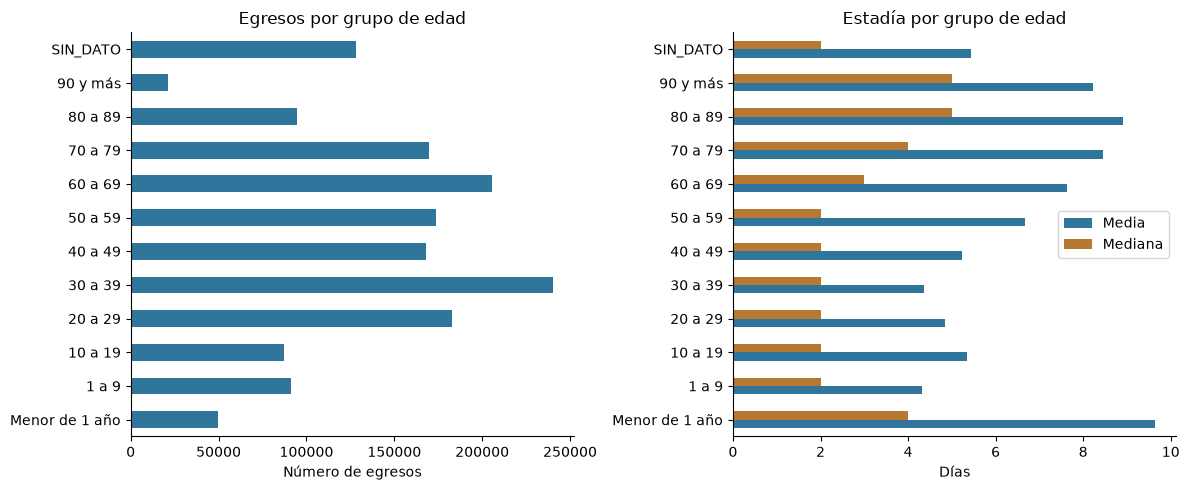

,registros,media_dias,mediana_dias
edad,,,
Menor de 1 año,39459,10.662,4.0
1 a 9,96875,3.883,2.0
10 a 19,94861,5.203,2.0
20 a 29,176766,4.368,2.0
30 a 39,243708,4.189,2.0
40 a 49,175306,5.322,2.0
50 a 59,183197,6.662,2.0
60 a 69,220643,7.429,3.0
70 a 79,183678,8.212,4.0

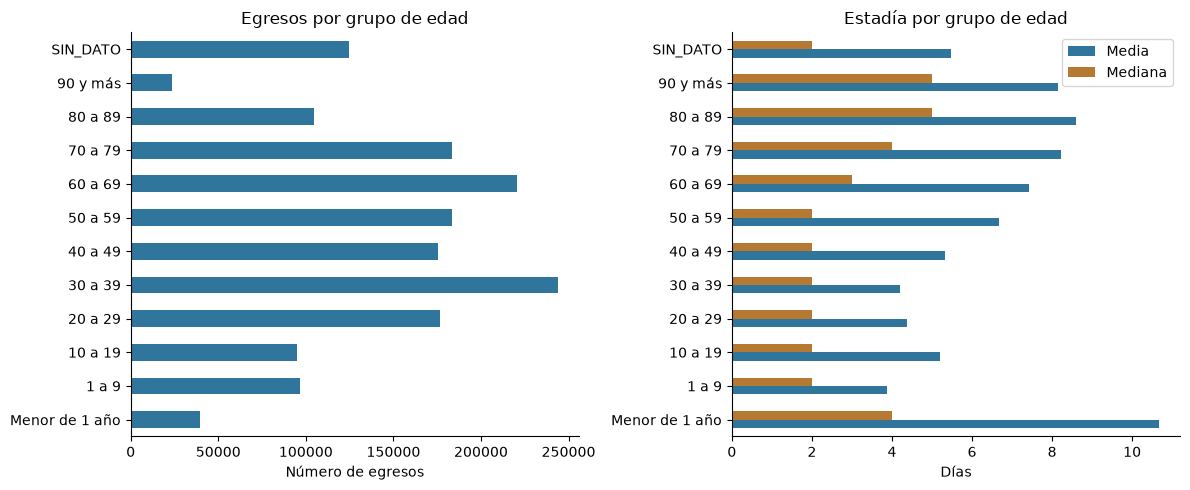

,registros,media_dias,mediana_dias
edad,,,
Menor de 1 año,38720,10.025,4.0
1 a 9,91789,4.106,2.0
10 a 19,99155,5.126,2.0
20 a 29,173457,4.502,2.0
30 a 39,247705,4.38,2.0
40 a 49,181362,5.168,2.0
50 a 59,188175,6.564,2.0
60 a 69,232597,7.296,3.0
70 a 79,195771,8.039,4.0

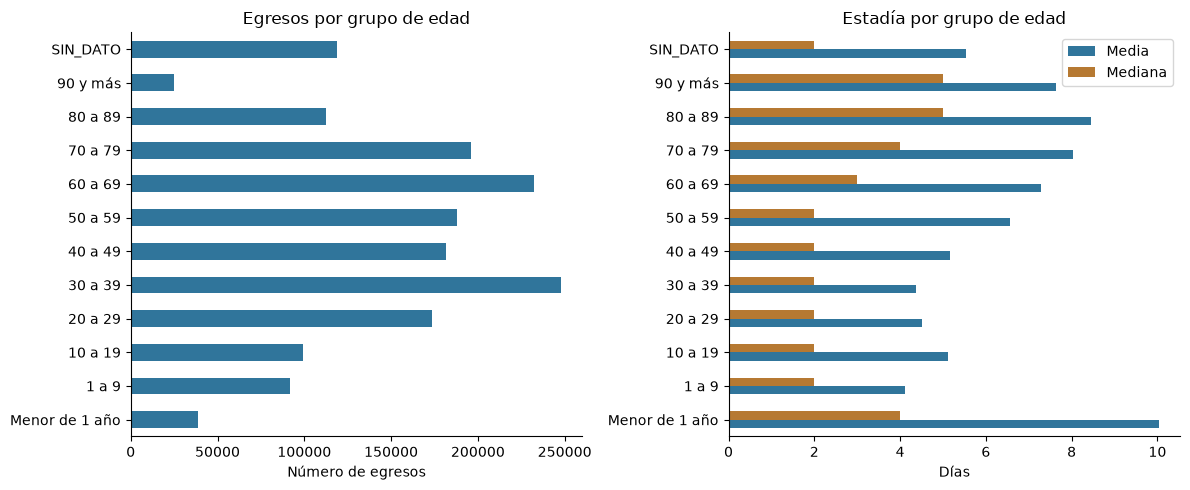

In [70]:
def mostrar_perfiles(datos, figuras):
    orden_edad = ["Menor de 1 año", "1 a 9", "10 a 19", "20 a 29", "30 a 39", "40 a 49",
                  "50 a 59", "60 a 69", "70 a 79", "80 a 89", "90 y más", "SIN_DATO"]
    perfil_edad = datos.assign(edad=datos["GRUPO_EDAD"].fillna("SIN_DATO")).groupby("edad").agg(
        registros=("ID_REGISTRO", "size"), media_dias=("DIAS_ESTADA", "mean"), mediana_dias=("DIAS_ESTADA", "median")
    ).reindex(orden_edad)
    perfil_diagnostico = datos.groupby(["DIAG1_CATEGORIA", "DIAG1_GLOSA_CATEGORIA"], dropna=False).agg(
        registros=("ID_REGISTRO", "size"), media_dias=("DIAS_ESTADA", "mean"), mediana_dias=("DIAS_ESTADA", "median")
    ).sort_values("registros", ascending=False)
    perfil_sexo = datos.groupby("SEXO", dropna=False).agg(
        registros=("ID_REGISTRO", "size"), media_dias=("DIAS_ESTADA", "mean"), mediana_dias=("DIAS_ESTADA", "median"))
    display(perfil_edad.round(3))
    display(perfil_diagnostico.head(15).round(3))
    display(perfil_sexo.round(3))

    fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
    perfil_edad["registros"].plot.barh(ax=ejes[0], color="#30759b")
    ejes[0].set(title="Egresos por grupo de edad", xlabel="Número de egresos", ylabel="")
    perfil_edad[["media_dias", "mediana_dias"]].plot.barh(ax=ejes[1], color=["#30759b", "#b67932"])
    ejes[1].set(title="Estadía por grupo de edad", xlabel="Días", ylabel="")
    ejes[1].legend(["Media", "Mediana"])
    fig.tight_layout()
    fig.savefig(figuras / "03_edad_y_estadia.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


reservar_salidas(mostrar_perfiles)

## 5. Verificación del resultado

Se comprueba la conservación de filas y variables, los ausentes y los cambios de contenido.
Una fila se cuenta como modificada si cambia algún valor o la representación de un faltante en los
campos presentes en el CSV. La conversión de tipo con el mismo valor textual y las columnas nuevas se
contabilizan aparte. Las filas afectadas por distintas transformaciones pueden coincidir; no se suman.
En la tabla de calidad, las medidas del original quedan vacías para las columnas añadidas.

Los cambios de las glosas derivadas se cuentan aparte; las glosas originales no se sustituyen.

In [71]:
def verificar_resultado(
    fuente, datos, calidad_inicial, repetidas_adicionales, valores_no_convertibles,
    resumen_geografico, filas_con_cambio_geografico, diagnosticos_pendientes,
):
    sin_cruce_por_variable = diagnosticos_pendientes.groupby("variable")["registros"].sum()

    columnas_comunes = fuente.columns.drop("ERROR", errors="ignore")
    filas_con_cambio = pd.Series(False, index=fuente.index)
    cambios_por_columna = {}
    for columna in fuente.columns:
        valores_finales = datos[columna].astype("string").fillna("<AUSENTE>")
        cambio = fuente[columna].ne(valores_finales)
        cambios_por_columna[columna] = int(cambio.sum())
        filas_con_cambio |= cambio
    registros_modificados = int(filas_con_cambio.sum())
    calidad_final = calidad_inicial.reindex(datos.columns)
    calidad_final["ausentes_finales"] = datos.isna().sum()
    calidad_final["porcentaje_ausente_final"] = 100 * calidad_final["ausentes_finales"] / len(datos)
    calidad_final["caracter_danado_final"] = datos.apply(
        lambda columna: columna.astype("string").str.contains("\ufffd", regex=False, na=False).sum())
    calidad_final["registros_con_cambio_contenido"] = pd.Series(cambios_por_columna)
    calidad_final["tipo_final"] = datos.dtypes.astype(str)

    resumen_procesamiento = pd.Series({
        "filas_originales": len(fuente),
        "filas_base_comun": len(datos),
        "filas_eliminadas": len(fuente) - len(datos),
        "filas_con_cambio_contenido": registros_modificados,
        "filas_sin_cambio_contenido": len(datos) - registros_modificados,
        "columnas_fuente": fuente.shape[1],
        "columnas_comunes": len(columnas_comunes),
        "columnas_comunes_conservadas": len(columnas_comunes.intersection(datos.columns)),
        "columnas_auxiliares": len(datos.columns.difference(fuente.columns.union(["ERROR"]))),
        "columnas_base_comun": datos.shape[1],
        "filas_con_asterisco_conservadas": int(datos["TIENE_ASTERISCO"].sum()),
        "repeticiones_adicionales_conservadas": repetidas_adicionales,
        "estadias_mayores_365_conservadas": int(datos["ESTADIA_MAYOR_365"].sum()),
        "DIAG1_sin_coincidencia_exacta": sin_cruce_por_variable.get("DIAG1", 0),
        "DIAG2_sin_coincidencia_exacta_entre_presentes": sin_cruce_por_variable.get("DIAG2", 0),
        "celdas_numericas_no_convertibles": sum(valores_no_convertibles.values()),
    }, name="cantidad").to_frame()
    resumen_procesamiento.loc["comunas_con_caracteres_reparados", "cantidad"] = resumen_geografico.loc["CORREGIDA", "COMUNA"]
    resumen_procesamiento.loc["regiones_con_caracteres_reparados", "cantidad"] = resumen_geografico.loc["CORREGIDA", "REGION"]
    resumen_procesamiento.loc["comunas_con_nombre_normalizado", "cantidad"] = resumen_geografico.loc["NORMALIZADA", "COMUNA"]
    resumen_procesamiento.loc["regiones_con_nombre_normalizado", "cantidad"] = resumen_geografico.loc["NORMALIZADA", "REGION"]
    resumen_procesamiento.loc["filas_con_cambio_en_glosas_derivadas", "cantidad"] = filas_con_cambio_geografico
    resumen_procesamiento.loc["comunas_sin_correspondencia", "cantidad"] = resumen_geografico.loc["SIN_CORRESPONDENCIA", "COMUNA"]
    resumen_procesamiento.loc["regiones_sin_correspondencia", "cantidad"] = resumen_geografico.loc["SIN_CORRESPONDENCIA", "REGION"]
    resumen_procesamiento.loc["filas_con_glosas_corregidas_aun_danadas", "cantidad"] = int(datos["TEXTO_DANADO_PENDIENTE"].sum())
    if "ERROR" in fuente:
        conteo_error = datos["ERROR"].value_counts()
        for valor in (0, 1):
            resumen_procesamiento.loc[f"filas_ERROR_{valor}_conservadas", "cantidad"] = conteo_error.get(valor, 0)
    resumen_procesamiento["cantidad"] = resumen_procesamiento["cantidad"].astype("int64")

    display(resumen_procesamiento)
    display(calidad_final.round(3))

    assert len(datos) == len(fuente), "La preparación común debe conservar todos los egresos."
    assert columnas_comunes.isin(datos.columns).all(), "Deben conservarse las 16 variables comunes."
    assert sum(valores_no_convertibles.values()) == 0, "Hay valores no convertibles que requieren revisión antes de exportar."

    return calidad_final, resumen_procesamiento


reservar_salidas(verificar_resultado)

,cantidad
filas_originales,1612267
filas_base_comun,1612267
filas_eliminadas,0
filas_con_cambio_contenido,1461467
filas_sin_cambio_contenido,150800
columnas_fuente,16
columnas_comunes,16
columnas_comunes_conservadas,16
columnas_auxiliares,19
columnas_base_comun,36


,cantidad
filas_originales,1667349
filas_base_comun,1667349
filas_eliminadas,0
filas_con_cambio_contenido,1514276
filas_sin_cambio_contenido,153073
columnas_fuente,16
columnas_comunes,16
columnas_comunes_conservadas,16
columnas_auxiliares,19
columnas_base_comun,36


,cantidad
filas_originales,1705514
filas_base_comun,1705514
filas_eliminadas,0
filas_con_cambio_contenido,1548749
filas_sin_cambio_contenido,156765
columnas_fuente,17
columnas_comunes,16
columnas_comunes_conservadas,16
columnas_auxiliares,19
columnas_base_comun,36


## 6. Informes por año

Se guardan las tablas de calidad, transformaciones y diagnósticos pendientes, junto con el resumen
y la descripción de las columnas. Las tablas y figuras de cada año quedan en `resultados/egresos_<año>/`.

In [72]:
def guardar_informes(
    tablas, datos, descripcion_variables, calidad_final, transformaciones,
    diagnosticos_pendientes, resumen_procesamiento,
):
    descripcion_auxiliares = {
        "ID_REGISTRO": "Número de fila del CSV, comenzando en 1 dentro de cada año",
        "ANO_FUENTE": "Año indicado por el nombre del ZIP del que se leyó la fila",
        "TIENE_ASTERISCO": "El registro tenía al menos un marcador * en la fuente",
        "TIENE_TEXTO_DANADO": "El registro tenía algún carácter de sustitución en la fuente",
        "EN_GRUPO_REPETIDO": "Los 16 campos comunes coinciden con los de al menos otra fila del mismo CSV",
        "DIAG2_VACIO_ORIGEN": "La causa externa estaba vacía en el CSV original",
        "TEXTO_DANADO_PENDIENTE": "Quedan caracteres de sustitución en las versiones corregidas de las glosas",
        "GLOSA_COMUNA_RESIDENCIA_CORREGIDA": "Nombre de comuna según CUT de la capa DPA 2023 de la SMA; conserva origen si no hay correspondencia",
        "GLOSA_REGION_RESIDENCIA_CORREGIDA": "Nombre de región según CUT de la capa DPA 2023 de la SMA; conserva origen si no hay correspondencia",
        "ESTADO_CORRECCION_COMUNA": "CORREGIDA, NORMALIZADA, COINCIDE, CATEGORIA_ESPECIAL, SIN_DATO o SIN_CORRESPONDENCIA",
        "ESTADO_CORRECCION_REGION": "CORREGIDA, NORMALIZADA, COINCIDE, CATEGORIA_ESPECIAL, SIN_DATO o SIN_CORRESPONDENCIA",
        "DIAG1_CATEGORIA": "Primeros tres caracteres del diagnóstico principal",
        "DIAG1_DESCRIPCION": "Descripción de subcategoría obtenida por coincidencia exacta",
        "DIAG1_GLOSA_CATEGORIA": "Descripción de categoría en el diccionario entregado",
        "DIAG1_CAPITULO": "Capítulo correspondiente a la categoría del diagnóstico principal",
        "DIAG1_GLOSA_CAPITULO": "Descripción del capítulo en el diccionario entregado",
        "DIAG1_COINCIDENCIA": "Coincidencia exacta, solo categoría, sin coincidencia o sin dato",
        "DIAG2_COINCIDENCIA": "Coincidencia exacta, sin coincidencia o sin dato en causa externa",
        "ESTADIA_MAYOR_365": "Más de 365 días; marca operativa de revisión, sin exclusión",
    }
    descripcion_final = descripcion_variables[["variable", "descripcion_diccionario"]].rename(
        columns={"descripcion_diccionario": "descripcion"})
    auxiliares = pd.Series(descripcion_auxiliares, name="descripcion").rename_axis("variable").reset_index()
    descripcion_final = pd.concat([descripcion_final, auxiliares], ignore_index=True).set_index("variable")
    descripcion_final = descripcion_final.reindex(datos.columns)
    descripcion_final["tipo_final"] = datos.dtypes.astype(str)
    columnas_originales = set(descripcion_variables["variable"])
    descripcion_final["origen"] = ["Fuente original" if columna in columnas_originales else "Derivada" for columna in datos.columns]
    descripcion_final.loc["ERROR", "descripcion"] = "Campo de significado sin documentar. Ausente en 2023 y 2024."
    descripcion_final.loc["ERROR", "origen"] = "CSV de 2025"

    descripcion_final.to_csv(tablas / "descripcion_variables.csv", encoding="utf-8-sig")
    calidad_final.to_csv(tablas / "calidad_datos.csv", encoding="utf-8-sig", float_format="%.6f")
    transformaciones.to_csv(tablas / "transformaciones.csv", index=False, encoding="utf-8-sig")
    diagnosticos_pendientes.to_csv(tablas / "diagnosticos_sin_coincidencia_exacta.csv", index=False, encoding="utf-8-sig")
    resumen_procesamiento.to_csv(tablas / "resumen_procesamiento.csv", encoding="utf-8-sig")

    print("Informes del año:", tablas.parent.relative_to(RAIZ))
    display(HTML("<strong>Muestra de la base preparada</strong>"))
    display(datos.head(5)[[
        "ANO_FUENTE", "ID_REGISTRO", "GRUPO_EDAD", "GLOSA_COMUNA_RESIDENCIA_CORREGIDA",
        "DIAG1_CATEGORIA", "DIAS_ESTADA", "ERROR",
    ]])


reservar_salidas(guardar_informes)

,ANO_FUENTE,ID_REGISTRO,GRUPO_EDAD,GLOSA_COMUNA_RESIDENCIA_CORREGIDA,DIAG1_CATEGORIA,DIAS_ESTADA,ERROR
0,2023,1,1 a 9,Iquique,D18,7,<NA>
1,2023,2,1 a 9,Iquique,T18,2,<NA>
2,2023,3,1 a 9,Iquique,K35,1,<NA>
3,2023,4,1 a 9,Iquique,K35,6,<NA>
4,2023,5,1 a 9,Iquique,K35,1,<NA>


,ANO_FUENTE,ID_REGISTRO,GRUPO_EDAD,GLOSA_COMUNA_RESIDENCIA_CORREGIDA,DIAG1_CATEGORIA,DIAS_ESTADA,ERROR
0,2024,1,10 a 19,La Serena,G00,14,<NA>
1,2024,2,60 a 69,Dalcahue,E14,22,<NA>
2,2024,3,60 a 69,Providencia,F31,1,<NA>
3,2024,4,70 a 79,La Florida,K40,1,<NA>
4,2024,5,60 a 69,La Florida,R07,7,<NA>


,ANO_FUENTE,ID_REGISTRO,GRUPO_EDAD,GLOSA_COMUNA_RESIDENCIA_CORREGIDA,DIAG1_CATEGORIA,DIAS_ESTADA,ERROR
0,2025,1,70 a 79,Hualaihué,I48,9,0
1,2025,2,60 a 69,Recoleta,K91,13,0
2,2025,3,50 a 59,Coquimbo,K80,1,0
3,2025,4,10 a 19,Huechuraba,H90,1,0
4,2025,5,60 a 69,Valparaíso,J44,8,0


## 7. Procesar los tres años

Esta función aplica las etapas anteriores a un ZIP y devuelve los datos de ese año para la escritura del Parquet.
El bucle de la siguiente celda la llama una vez por cada archivo. Cada etapa llena el espacio reservado para ese año.

In [73]:
def procesar_anio(anio, nombre_csv, codificacion):
    resultados = RAIZ / "resultados" / f"egresos_{anio}"
    tablas = resultados / "tablas"
    figuras = resultados / "figuras"
    for carpeta in (tablas, figuras):
        carpeta.mkdir(parents=True, exist_ok=True)

    fuente, originales, cie10, descripcion_variables = ejecutar_etapa(
        anio, cargar_fuente, anio, nombre_csv, codificacion,
    )
    ejecutar_etapa(anio, explorar_fuente, originales, figuras)
    calidad_inicial, en_grupo_repetido, repetidas_adicionales = ejecutar_etapa(
        anio, revisar_calidad, fuente, originales, figuras,
    )
    datos, transformaciones, valores_no_convertibles = ejecutar_etapa(
        anio, transformar_datos, fuente, originales, en_grupo_repetido, anio,
    )
    transformaciones, resumen_geografico, filas_con_cambio_geografico = ejecutar_etapa(
        anio, corregir_glosas_geograficas, datos, transformaciones,
    )
    diagnosticos_pendientes = ejecutar_etapa(anio, incorporar_cie10, datos, originales, cie10)

    ejecutar_etapa(anio, revisar_inconsistencias, datos, anio, valores_no_convertibles)
    ejecutar_etapa(anio, mostrar_perfiles, datos, figuras)
    calidad_final, resumen_procesamiento = ejecutar_etapa(
        anio, verificar_resultado, fuente, datos, calidad_inicial, repetidas_adicionales,
        valores_no_convertibles, resumen_geografico, filas_con_cambio_geografico, diagnosticos_pendientes,
    )
    ejecutar_etapa(
        anio, guardar_informes, tablas, datos, descripcion_variables, calidad_final, transformaciones,
        diagnosticos_pendientes, resumen_procesamiento,
    )
    return datos

### Recorrido y escritura de la base común

PyArrow escribe un año a la vez en el mismo archivo temporal. Al terminar cada año se libera
su tabla de memoria. Se comprueba que el esquema sea compatible y se lee `ANO_FUENTE` del
archivo temporal para verificar los conteos. Solo después se reemplaza la base común.

In [74]:
with TemporaryDirectory(dir=PROCESADOS) as carpeta_temporal:
    temporal = Path(carpeta_temporal) / ARCHIVO_COMUN.name
    esquema = None
    with ExitStack() as recursos:
        for anio, (nombre_csv, codificacion) in FUENTES.items():
            datos = procesar_anio(anio, nombre_csv, codificacion)
            tabla = pa.Table.from_pandas(datos, preserve_index=False)
            del datos
            if esquema is None:
                esquema = tabla.schema
                salida = recursos.enter_context(pq.ParquetWriter(temporal, esquema))
            elif not tabla.schema.equals(esquema):
                raise ValueError(f"Las columnas de {anio} tienen un esquema distinto al de la base común.")
            salida.write_table(tabla)
            del tabla

    with pq.ParquetFile(temporal) as base:
        if not base.schema_arrow.equals(esquema):
            raise ValueError("El esquema del Parquet temporal difiere del que se escribió.")
        conteos = base.read(columns=["ANO_FUENTE"])["ANO_FUENTE"].value_counts().to_pylist()

    filas_por_anio = {grupo["values"]: grupo["counts"] for grupo in conteos}
    if filas_por_anio != FILAS_ESPERADAS:
        raise ValueError(f"Egresos esperados: {FILAS_ESPERADAS}. Egresos obtenidos: {filas_por_anio}.")

    temporal.replace(ARCHIVO_COMUN)

print("Base común guardada:", ARCHIVO_COMUN.relative_to(RAIZ))
print(f"Total de egresos verificados: {sum(filas_por_anio.values()):,}")
display(pd.Series(filas_por_anio, name="egresos").rename_axis("ANO_FUENTE").to_frame())

Base común guardada: datos\procesados\egresos_2023_2025_base_comun.parquet
Total de egresos verificados: 4,985,130


,egresos
ANO_FUENTE,
2023,1612267
2024,1667349
2025,1705514


Los códigos diagnósticos sin correspondencia se conservan para revisión. Las glosas geográficas
originales y corregidas permiten rastrear los cambios. `ANO_FUENTE` identifica el ZIP aunque
`ANO_EGRESO` esté ausente. Se conservan las repeticiones y las estadías extremas.

Fuente de cada año: ZIP y diccionario entregados por el equipo, identificados por SHA-256 al cargar.
[DEIS: definición de diagnóstico principal de egreso](https://repositoriodeis.minsal.cl/deis/rem_base/ver.asp?var3=9).

### Vista previa de la base común

Se muestran las primeras 10 filas del Parquet final con todas sus columnas.

In [75]:
with pq.ParquetFile(ARCHIVO_COMUN) as base:
    muestra = next(base.iter_batches(batch_size=10)).to_pandas()

display(muestra)

,ID_REGISTRO,ANO_FUENTE,PERTENENCIA_ESTABLECIMIENTO_SALU,SEXO,GRUPO_EDAD,ETNIA,GLOSA_PAIS_ORIGEN,COMUNA_RESIDENCIA,GLOSA_COMUNA_RESIDENCIA,REGION_RESIDENCIA,GLOSA_REGION_RESIDENCIA,PREVISION,GLOSA_PREVISION,ANO_EGRESO,DIAG1,DIAG2,DIAS_ESTADA,CONDICION_EGRESO,ERROR,TIENE_ASTERISCO,TIENE_TEXTO_DANADO,EN_GRUPO_REPETIDO,DIAG2_VACIO_ORIGEN,TEXTO_DANADO_PENDIENTE,GLOSA_COMUNA_RESIDENCIA_CORREGIDA,ESTADO_CORRECCION_COMUNA,GLOSA_REGION_RESIDENCIA_CORREGIDA,ESTADO_CORRECCION_REGION,DIAG1_CATEGORIA,DIAG1_DESCRIPCION,DIAG1_GLOSA_CATEGORIA,DIAG1_CAPITULO,DIAG1_GLOSA_CAPITULO,DIAG1_COINCIDENCIA,DIAG2_COINCIDENCIA,ESTADIA_MAYOR_365
0,1,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,D180,<NA>,7,1,<NA>,False,False,False,True,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,D18,"HEMANGIOMA, DE CUALQUIER SITIO",Hemangioma y linfangioma de cualquier sitio,C00-D48,Tumores [Neoplasias],SUBCATEGORIA_EXACTA,SIN_DATO,False
1,2,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,T181,W449,2,1,<NA>,False,False,False,False,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,T18,CUERPO EXTRAÑO EN EL ESOFAGO,Cuerpo extraño en el tubo digestivo,S00-T98,"Traumatismos, envenenamientos y algunas otras consecuencias de causas externas",SUBCATEGORIA_EXACTA,SUBCATEGORIA_EXACTA,False
2,3,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,K358,<NA>,1,1,<NA>,False,False,True,True,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,K35,OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS,Apendicitis aguda,K00-K93,Enfermedades del sistema digestivo,SUBCATEGORIA_EXACTA,SIN_DATO,False
3,4,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,K353,<NA>,6,1,<NA>,False,False,False,True,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,K35,APENDICITIS AGUDA CON PERITONITIS LOCALIZADA,Apendicitis aguda,K00-K93,Enfermedades del sistema digestivo,SUBCATEGORIA_EXACTA,SIN_DATO,False
4,5,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,K353,<NA>,1,1,<NA>,False,False,False,True,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,K35,APENDICITIS AGUDA CON PERITONITIS LOCALIZADA,Apendicitis aguda,K00-K93,Enfermedades del sistema digestivo,SUBCATEGORIA_EXACTA,SIN_DATO,False
5,6,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,K358,<NA>,3,1,<NA>,False,False,True,True,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,K35,OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS,Apendicitis aguda,K00-K93,Enfermedades del sistema digestivo,SUBCATEGORIA_EXACTA,SIN_DATO,False
6,7,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,T232,X159,5,1,<NA>,False,False,False,False,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,T23,"QUEMADURA DE LA MUÑECA Y DE LA MANO, DE SEGUNDO GRADO",Quemadura y corrosión de la muñeca y de la mano,S00-T98,"Traumatismos, envenenamientos y algunas otras consecuencias de causas externas",SUBCATEGORIA_EXACTA,SUBCATEGORIA_EXACTA,False
7,8,2023,"Pertenecientes al Sistema Nacional de Servicios de Salud, SNSS",HOMBRE,1 a 9,No se identifica con alguna etnia,Chileno,01101,Iquique,01,De Tarapacá,1,FONASA,2023,K358,<NA>,1,1,<NA>,False,False,True,True,False,Iquique,COINCIDE,Tarapacá,NORMALIZADA,K35,OTRAS APENDICITIS AGUDAS Y LAS NO ESPECIFICADAS,Apendicitis aguda,K00-K93,Enfermedades del sistema digestivo,SUBCATEGORIA_EXACTA,